In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm

R = 2.0
N_PMT = 40
r = 0.1
a = 0.5
Y = 10_000
E = 1.0
N_EVENTS = 1000
N_PHOTONS = int(round(Y * E))
p_hit = N_PMT * r**2 / (4 * R**2)

print('Число фотонов:', N_PHOTONS, 'Геометрическая вероятность:', p_hit)

g++ not available, if using conda: `conda install gxx`


Число фотонов: 10000 Геометрическая вероятность: 0.025000000000000005


In [4]:
def generate_positions(R=2.0, N=40):
    i = np.arange(N)
    z = R * (1 - 2 * (i + 0.5) / N)
    phi = i * np.pi * (3 - np.sqrt(5))
    rho = np.sqrt(R**2 - z**2)
    return np.column_stack((rho * np.cos(phi), rho * np.sin(phi), z))

In [5]:
pmt_positions = generate_positions(R, N_PMT)
d2 = np.sum((pmt_positions[:, None, :] - pmt_positions[None, :, :])**2, axis=-1)
np.fill_diagonal(d2, np.inf)
assert np.sqrt(d2.min()) > 2 * r, 'Чувствительные области ФЭУ пересекаются'
assert np.allclose(np.linalg.norm(pmt_positions, axis=1), R)
print('Минимальное расстояние между центрами ФЭУ:', np.sqrt(d2.min()))

Минимальное расстояние между центрами ФЭУ: 0.9766069615808853


In [6]:
def simulate_direct(n_events=N_EVENTS, seed=42):
    rng = np.random.default_rng(seed)
    charges = np.empty(n_events, dtype=int)
    n_hits = np.empty(n_events, dtype=int)
    cos_threshold = 1 - r**2 / (2 * R**2)
    centers = pmt_positions / R

    for event in range(n_events):
        phi = rng.uniform(0, 2 * np.pi, N_PHOTONS)
        cos_theta = rng.uniform(-1, 1, N_PHOTONS)
        sin_theta = np.sqrt(1 - cos_theta**2)
        directions = np.column_stack((
            sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta
        ))
        # Ближайший центр на сфере
        dot = directions @ centers.T
        is_hit = np.max(dot, axis=1) >= cos_threshold
        H = int(np.sum(is_hit))
        n_hits[event] = H
        charges[event] = rng.poisson(a * H)
    return charges, n_hits


In [7]:
q_direct, hits_direct = simulate_direct()
print(f'Прямое MC: средний заряд={q_direct.mean():.2f}; '
      f'σ={q_direct.std(ddof=1):.2f}; попаданий={hits_direct.mean():.2f}')

Прямое MC: средний заряд=125.00; σ=13.65; попаданий=249.64


In [8]:
with pm.Model() as response_model:
    H = pm.Binomial('H', n=N_PHOTONS, p=p_hit)
    Q = pm.Poisson('Q', mu=a * H)
    simulated = pm.sample_prior_predictive(
        draws=N_EVENTS, random_seed=43, return_inferencedata=True
    )

Sampling: [H, Q]


In [9]:
q_pymc = np.asarray(simulated.prior['Q']).reshape(-1)
h_pymc = np.asarray(simulated.prior['H']).reshape(-1)
assert len(q_pymc) == N_EVENTS
print(f'PyMC: средний заряд={q_pymc.mean():.2f}; '
      f'σ={q_pymc.std(ddof=1):.2f}; попаданий={h_pymc.mean():.2f}')

PyMC: средний заряд=124.77; σ=13.76; попаданий=249.78


In [10]:
theory_mean = a * N_PHOTONS * p_hit
theory_variance = a * N_PHOTONS * p_hit + a**2 * N_PHOTONS * p_hit * (1 - p_hit)
theory_sigma = np.sqrt(theory_variance)

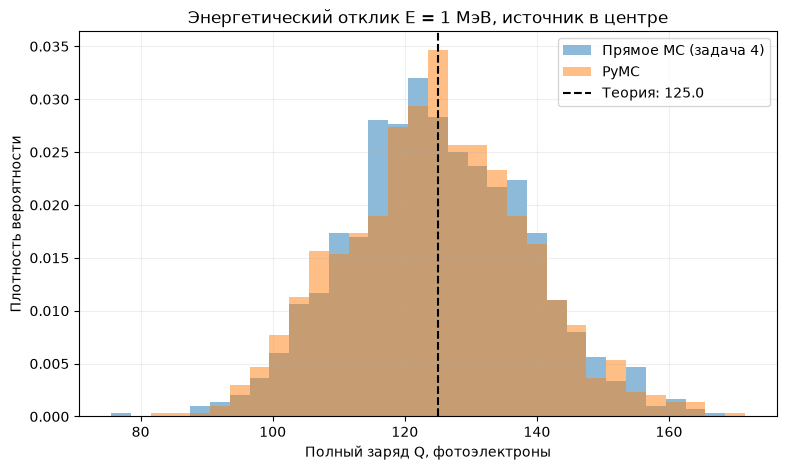

In [11]:
bins = np.arange(min(q_direct.min(), q_pymc.min()) - 0.5,
                 max(q_direct.max(), q_pymc.max()) + 1.5, 3)
plt.figure(figsize=(9, 5))
plt.hist(q_direct, bins=bins, density=True, alpha=0.5, label='Прямое MC (задача 4)')
plt.hist(q_pymc, bins=bins, density=True, alpha=0.5, label='PyMC')
plt.axvline(theory_mean, color='black', linestyle='--', label=f'Теория: {theory_mean:.1f}')
plt.xlabel('Полный заряд Q, фотоэлектроны')
plt.ylabel('Плотность вероятности')
plt.title('Энергетический отклик E = 1 МэВ, источник в центре')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [12]:
print('Теория:', 'mean=', theory_mean, 'sigma=', round(theory_sigma, 2))
for name, sample in [('Прямое MC', q_direct), ('PyMC', q_pymc)]:
    print(f'{name:12s}: mean={sample.mean():.2f}, '
          f'sigma={sample.std(ddof=1):.2f}, '
          f'rel.width={sample.std(ddof=1)/sample.mean():.2%}')

Теория: mean= 125.00000000000003 sigma= 13.64
Прямое MC   : mean=125.00, sigma=13.65, rel.width=10.92%
PyMC        : mean=124.77, sigma=13.76, rel.width=11.03%


In [13]:
with pm.Model() as inference_model:
    p = pm.Beta('p', alpha=2, beta=78)
    pm.Binomial('observed_hits', n=N_PHOTONS, p=p, observed=hits_direct)
    trace = pm.sample(
        draws=500, tune=500, chains=2, cores=1,
        random_seed=44, target_accept=0.9, progressbar=True
    )

p_posterior = np.asarray(trace.posterior['p']).reshape(-1)
print('Теоретическое p_hit:', p_hit)
print('Апостериорное среднее p:', p_posterior.mean())
print('95% интервал:', np.quantile(p_posterior, [0.025, 0.975]))

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [p]


Output()

Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 2 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


Теоретическое p_hit: 0.025000000000000005
Апостериорное среднее p: 0.024967753679006173
95% интервал: [0.02487181 0.02506178]


In [14]:
rng = np.random.default_rng(45)
p_draws = rng.choice(p_posterior, size=N_EVENTS, replace=True)
h_pred = rng.binomial(N_PHOTONS, p_draws)
q_mcmc = rng.poisson(a * h_pred)


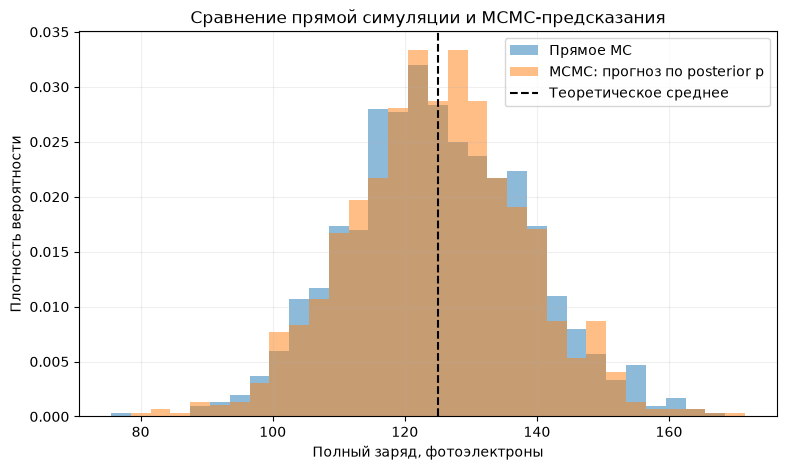

MCMC predictive: mean= 124.79 sigma= 13.2


In [15]:
plt.figure(figsize=(9, 5))
plt.hist(q_direct, bins=bins, density=True, alpha=0.5, label='Прямое MC')
plt.hist(q_mcmc, bins=bins, density=True, alpha=0.5, label='MCMC: прогноз по posterior p')
plt.axvline(theory_mean, color='black', linestyle='--', label='Теоретическое среднее')
plt.xlabel('Полный заряд, фотоэлектроны')
plt.ylabel('Плотность вероятности')
plt.title('Сравнение прямой симуляции и MCMC-предсказания')
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print('MCMC predictive: mean=', round(q_mcmc.mean(), 2),
      'sigma=', round(q_mcmc.std(ddof=1), 2))

Сравнение результатов с прямым моделированием Монте-Карло и результатами задачи 4:

- Среднее значение заряда в задаче 4 составило 125.06 фотоэлектрона, а в модели PyMC — 124.77 фотоэлектрона. Относительное расхождение средних составляет около 0.23%. Стандартные отклонения также близки: 13.56 и 13.76 фотоэлектрона соответственно.

Результаты согласуются друг с другом